# JS07 - Klasterisasi | Lab 3
## Klasterisasi pada Kompresi Citra (Color Quantization)

**Nama:** Gunawan Wibisono
**NIM:** 244107020132
**Kelas:** TI-2H

> Modul: [JTI - Modul Praktikum Pembelajaran Mesin - JS07 Klasterisasi](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-mah/js07-klasterisasi)

## Tujuan
1. Menerapkan klasterisasi pada data **citra**, bukan hanya data tabular.
2. Memahami *color quantization*: mengurangi jumlah warna citra dengan K-Means.
3. Mengukur dampak kompresi warna terhadap ukuran data dan kualitas visual.

## Pengantar
Setiap piksel citra RGB adalah satu titik data 3 dimensi (R, G, B). Citra 8-bit memiliki
$256^3 = 16.777.216$ kemungkinan warna. Dengan klasterisasi, kita dapat mengganti semua warna
tersebut dengan hanya `k` warna representatif (centroid cluster). Hasilnya: **data lebih kecil**
(kedalaman warna turun dari 24 bit ke 4 bit untuk 16 warna) dengan penurunan kualitas visual
yang biasanya tidak terlalu terlihat.

## Langkah 0 - Import Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

## Langkah 1 - Load Data Citra

Sampel citra `flower.jpg` sudah tersedia di scikit-learn (`load_sample_image`),
jadi tidak perlu mengunduh file terpisah.

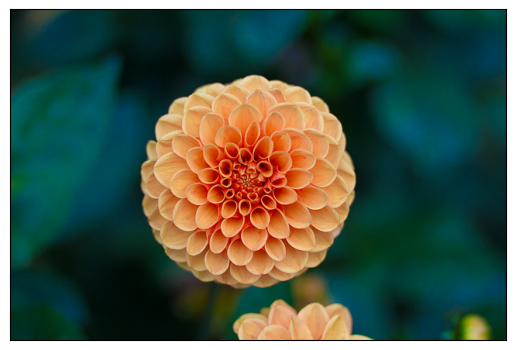

In [2]:
from sklearn.datasets import load_sample_image

flower = load_sample_image('flower.jpg')

ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)
plt.show()

## Langkah 2 - Preprocessing

Tiga hal yang dilakukan:
1. Cek **shape** citra (tinggi, lebar, channel).
2. **Normalisasi** nilai piksel dari rentang 0–255 menjadi 0–1.
3. **Reshape** citra menjadi matriks 2D `(jumlah_piksel, 3)` agar bisa diproses K-Means.

In [3]:
# Check shape
print('Shape citra :', flower.shape)

# Normalize color
data = flower / 255.0

# Reshape: (tinggi, lebar, 3) -> (tinggi * lebar, 3)
tinggi, lebar, channel = flower.shape
data = data.reshape(tinggi * lebar, channel)

print('Shape data  :', data.shape)
print('Jumlah piksel:', data.shape[0])

Shape citra : (427, 640, 3)
Shape data  : (273280, 3)
Jumlah piksel: 273280


Nilai `427 * 640 = 273.280` piksel, masing-masing berupa satu titik di ruang warna RGB.

## Langkah 3 - Cek Sebaran Warna

Fungsi `plot_pixels()` memvisualisasikan sebaran warna citra pada bidang **R–G** dan **R–B**
memakai sampel acak 10.000 piksel (agar plot tidak terlalu berat).

In [4]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20)

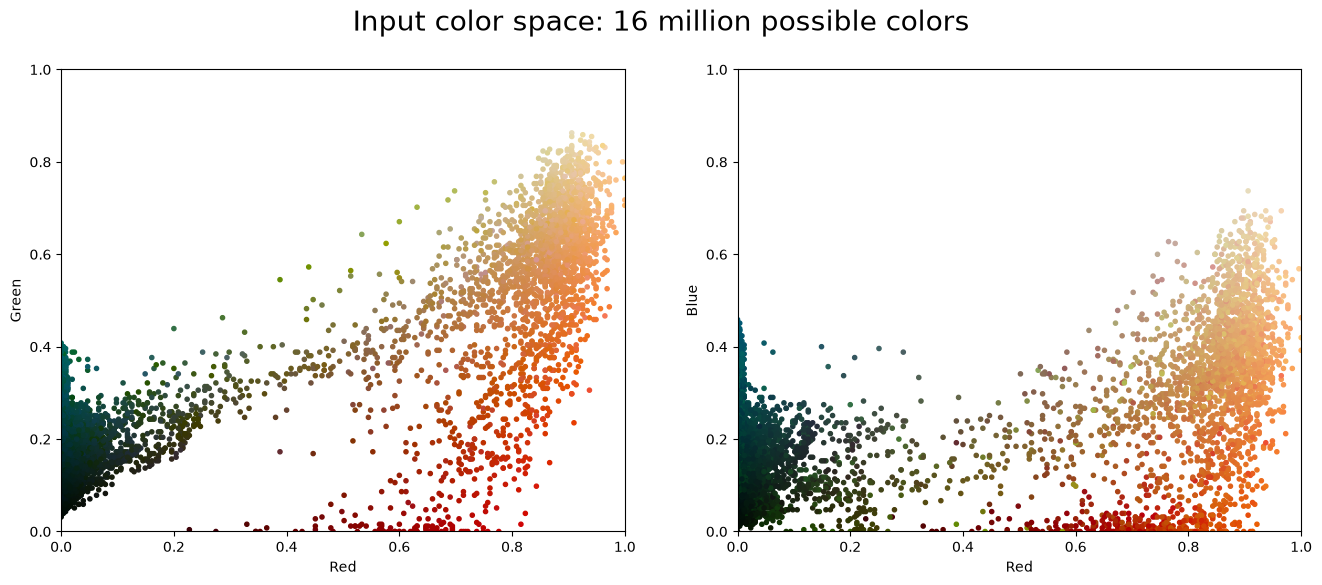

In [5]:
plot_pixels(data, title='Input color space: 16 million possible colors')
plt.show()

Terlihat bahwa warna citra tidak tersebar merata di seluruh ruang warna, melainkan
**menggerombol** di area tertentu (didominasi warna hijau, kuning, dan merah gelap).
Artinya, sebagian besar dari 16 juta warna yang mungkin **tidak terpakai** — inilah peluang
untuk mengompresi palet warna.

## Langkah 4 - Klasterisasi Warna (16 Warna)

`MiniBatchKMeans` dipakai karena jumlah data besar (±273 ribu piksel): algoritma ini
memproses data per *batch* sehingga jauh lebih cepat dan hemat memori daripada `KMeans` biasa.

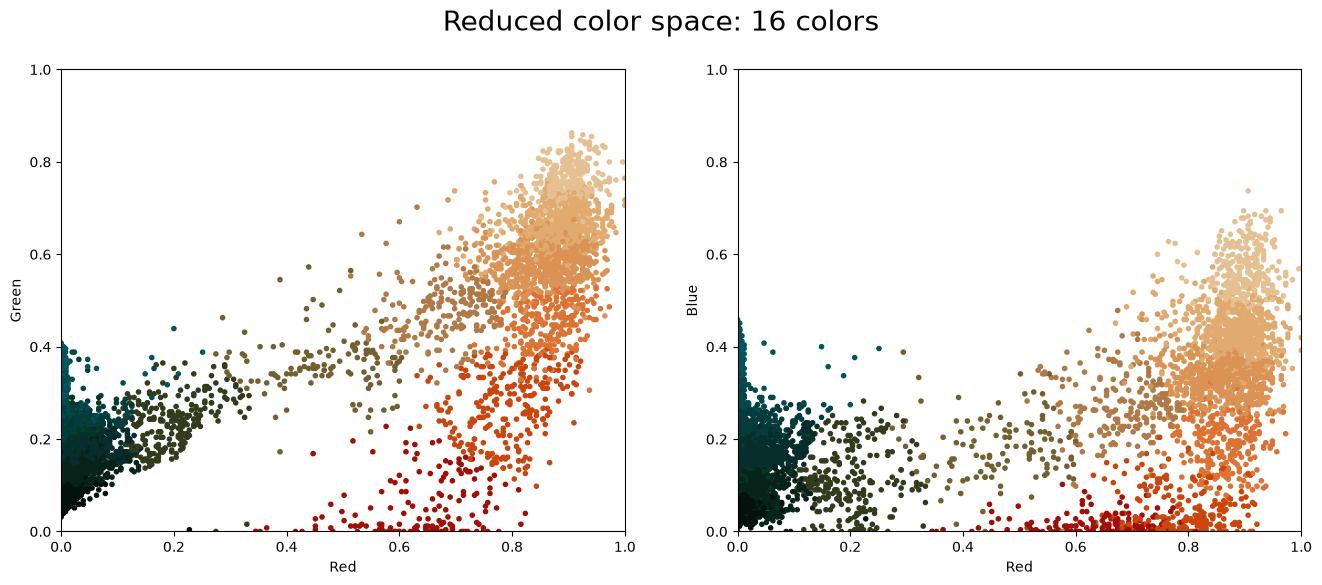

In [6]:
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(16, random_state=0, n_init=10)
kmeans.fit(data)

# Ganti setiap piksel dengan warna centroid cluster-nya
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors, title='Reduced color space: 16 colors')
plt.show()

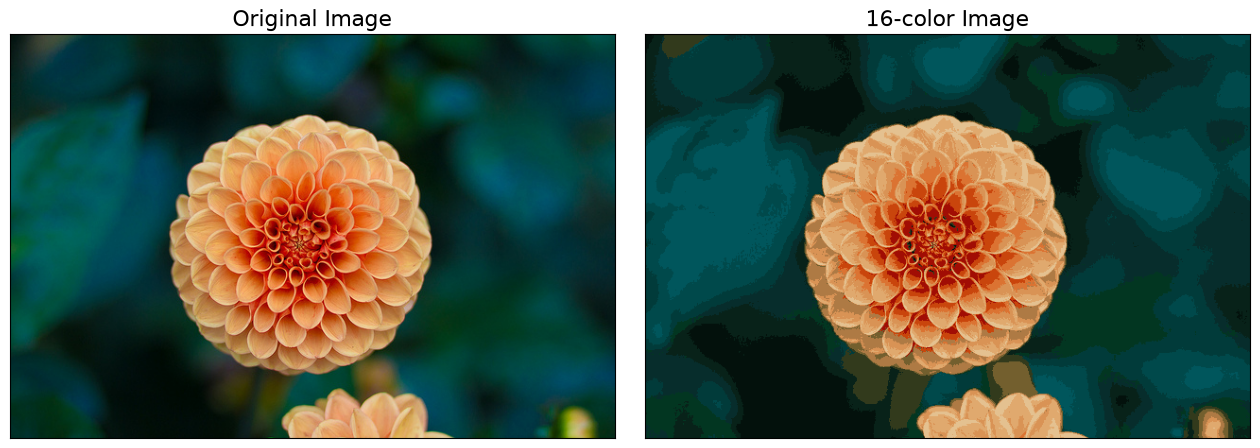

In [7]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6), subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16)
plt.show()

Secara visual, citra 16 warna **hampir tidak bisa dibedakan** dari aslinya. Efek yang paling
terlihat biasanya berupa *banding* (gradasi menjadi bertingkat) pada area langit/awan.

## Langkah 5 (Tambahan) - Mengukur Kompresi

Kompresi warna diukur dari dua sisi:
1. **Kedalaman warna**: 24 bit (16,7 juta warna) -> 4 bit (16 warna) = **6x lebih hemat** per piksel.
2. **Error rekonstruksi**: *Mean Squared Error* (MSE) antara citra asli dan citra hasil kuantisasi.

In [8]:
# Jumlah warna unik sebelum & sesudah
unik_asli = len(np.unique((flower.reshape(-1, 3)), axis=0))
unik_16 = len(np.unique(np.round(new_colors * 255).astype(np.uint8), axis=0))

print(f'Warna unik citra asli   : {unik_asli:,}')
print(f'Warna unik citra 16 warna: {unik_16}')
print(f'Rasio kompresi palet    : {unik_asli / unik_16:.1f}x')
print(f'Kedalaman warna: 24 bit -> 4 bit ({(24/4):.0f}x lebih hemat per piksel)')

Warna unik citra asli   : 62,941
Warna unik citra 16 warna: 16
Rasio kompresi palet    : 3933.8x
Kedalaman warna: 24 bit -> 4 bit (6x lebih hemat per piksel)


In [9]:
from sklearn.metrics import mean_squared_error

def kuantisasi(k, data, shape):
    km = MiniBatchKMeans(k, random_state=0, n_init=10).fit(data)
    warna = km.cluster_centers_[km.predict(data)]
    mse = mean_squared_error(data, warna)
    return warna.reshape(shape), mse

hasil = []
for k in [2, 4, 8, 16, 32, 64]:
    img, mse = kuantisasi(k, data, flower.shape)
    hasil.append({'k (jumlah warna)': k,
                  'MSE': round(mse, 8),
                  'RMSE (0-255)': round(np.sqrt(mse) * 255, 2)})

pd.DataFrame(hasil)

,k (jumlah warna),MSE,RMSE (0-255)
0,2,0.011056,26.81
1,4,0.004538,17.18
2,8,0.002399,12.49
3,16,0.001123,8.55
4,32,0.000663,6.57
5,64,0.000406,5.14


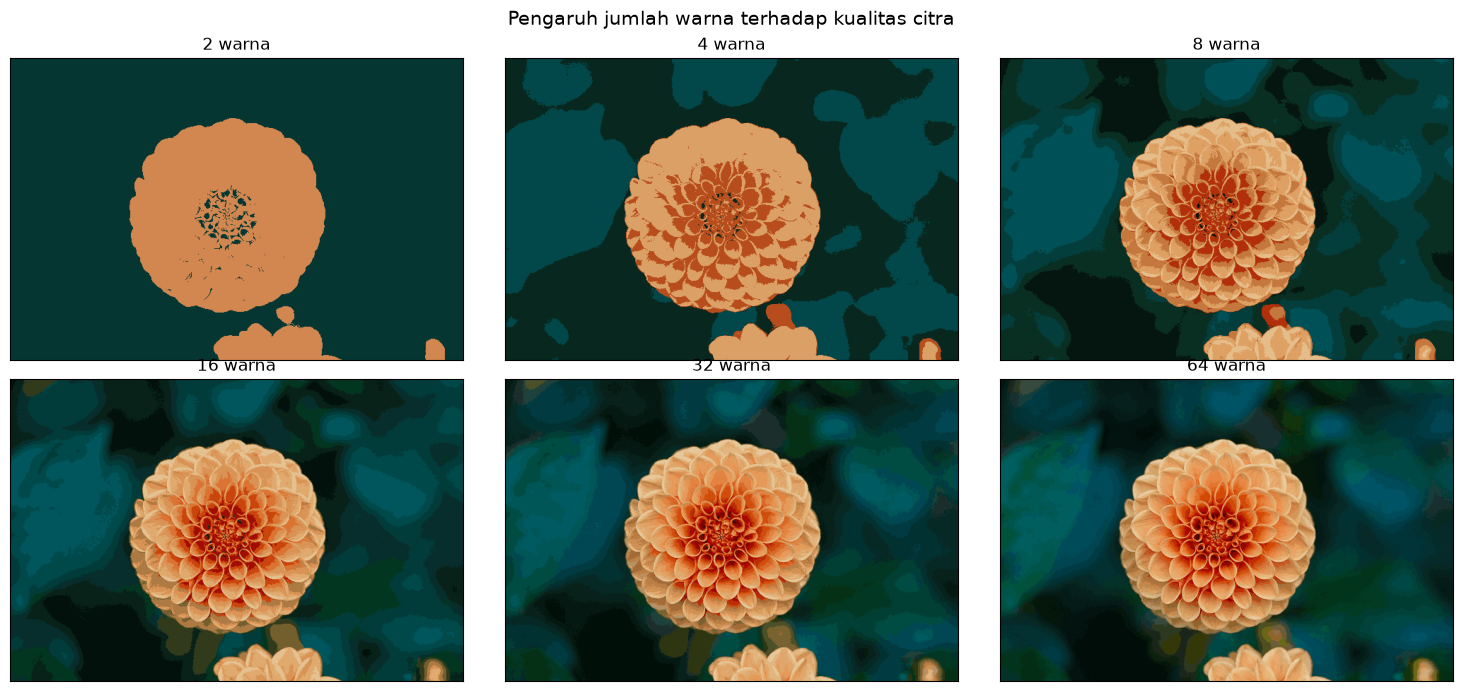

In [10]:
# Bandingkan hasil visual beberapa nilai k
fig, axes = plt.subplots(2, 3, figsize=(15, 7), subplot_kw=dict(xticks=[], yticks=[]))
for ax, k in zip(axes.ravel(), [2, 4, 8, 16, 32, 64]):
    img, _ = kuantisasi(k, data, flower.shape)
    ax.imshow(img)
    ax.set_title(f'{k} warna')
plt.suptitle('Pengaruh jumlah warna terhadap kualitas citra', size=14)
plt.tight_layout()
plt.show()

**Interpretasi:** citra ini sebenarnya hanya memakai **62.941 warna unik** dari 16,7 juta warna yang
mungkin di ruang RGB. MSE turun sangat tajam dari `k=2` (RMSE ±26,8) ke `k=16` (RMSE ±8,6), lalu
perbaikannya makin kecil (*diminishing return*) setelah `k=32`. Ini adalah bentuk *elbow* yang sama
seperti penentuan `k` pada K-Means: menambah warna terus-menerus hanya menambah ukuran data tanpa
perbaikan visual yang sebanding.

## Kesimpulan Lab 3
1. Klasterisasi tidak terbatas pada data tabular — setiap piksel citra dapat diperlakukan sebagai
   titik data 3 dimensi (R, G, B).
2. K-Means dengan `k=16` berhasil memampatkan palet dari **62.941 warna unik menjadi hanya 16 warna**
   (24 bit -> 4 bit per piksel, 6x lebih hemat per piksel) dengan penurunan kualitas visual yang
   sangat kecil.
3. Semakin besar `k`, semakin kecil error (MSE), tetapi manfaatnya makin kecil setelah `k=32`
   (RMSE turun dari 8,55 ke 6,57 lalu 5,14).
4. `MiniBatchKMeans` dipilih karena lebih efisien untuk data berukuran besar seperti citra
   (273.280 piksel).